# 01_EDA: Khám phá dữ liệu FreshRetailNet-50K

**Project:** Machine Learning-Based Dynamic Pricing Optimization for Fresh Retail
**Phục vụ:** Chương 3 (mục 3.1 và 3.2) của báo cáo

| Phần | Nội dung | Dùng cho |
|---|---|---|
| 0 | Cấu hình, nạp dữ liệu, kiểm tra chất lượng | 3.1, 3.3 |
| 1 | Tổng quan dataset | Bảng 3.1 |
| EDA 1 | Sales: phân phối, theo thời gian, theo ngành / sản phẩm | 3.2 |
| EDA 2 | Discount: phân phối, tần suất, quan hệ với cầu | 3.2 |
| EDA 3 | Stockout: tỷ lệ hết hàng, cầu bị che khuất | 3.2, 3.3 |
| EDA 4 | Promotion, holiday, thời tiết | 3.2 |
| EDA 5 | Price elasticity: fixed effects, sai số chuẩn cluster, theo ngành | 3.2, Chương 5 |
| Tổng kết | Các phát hiện chính, file đã lưu | Báo cáo + notebook 02 |

**Đầu ra** (lưu trong `OUT_DIR`):
- `data/daily.parquet`: bảng theo ngày (không có cột theo giờ), dùng cho notebook 02
- `figures/*.png`: hình cho báo cáo (dpi 200)
- `tables/*.csv`: bảng tổng quan, độ co giãn theo ngành (dùng ở Chương 5 và demo)
- `tables/eda_summary.json`: các con số chính

> Chọn *Runtime → Change runtime type → High-RAM* nếu có. Notebook bỏ cột theo giờ khi nạp bảng chính nên bản 12 GB vẫn chạy được.

In [1]:
!pip install -q -U datasets

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from datasets import load_dataset

# ---- Cấu hình ----
USE_DRIVE = True          # True: lưu kết quả vào Google Drive để các notebook sau dùng lại
PROJECT = "Dynamic_Pricing_Project"
RANDOM_STATE = 42
STOCKOUT_HEAVY_HOURS = 8  # ngày hết hàng >= 8 giờ coi là "hết hàng nặng"
MIN_VALID_DISCOUNT = 0.3  # discount < 0,3 (giảm trên 70%) coi là dữ liệu lỗi, loại khỏi hồi quy

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive") / PROJECT
    except ImportError:
        OUT_DIR = Path(PROJECT)
else:
    OUT_DIR = Path(PROJECT)
for sub in ["data", "figures", "tables"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
print("Lưu kết quả tại:", OUT_DIR.resolve())

# ---- Phong cách biểu đồ (thống nhất cho cả báo cáo) ----
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"   # màu series 1, 2, 3
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e4df", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 6,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

SUMMARY = {}  # các con số chính, lưu ra JSON ở cuối

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / "figures" / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

def pct_axis(ax, axis="y", decimals=None):
    fmt = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

Mounted at /content/drive
Lưu kết quả tại: /content/drive/MyDrive/Dynamic_Pricing_Project


## 0. Nạp dữ liệu và kiểm tra chất lượng

Bảng chính bỏ 2 cột chuỗi theo giờ (`hours_sale`, `hours_stock_status`) để tiết kiệm RAM. EDA 3 nạp lại cột theo giờ cho một mẫu.

In [3]:
ds = load_dataset("Dingdong-Inc/FreshRetailNet-50K")
print(ds)

README.md:   0%|          | 0.00/4.88k [00:00<?, ?B/s]

data/train.parquet: reconstructing file:   0%|          |  0.00B /  106MB            

data/train.parquet: downloading bytes:           |  0.00B            

data/eval.parquet: reconstructing file:   0%|          |  0.00B / 8.44MB            

data/eval.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4500000 [00:00<?, ? examples/s]

Generating eval split:   0%|          | 0/350000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level'],
        num_rows: 4500000
    })
    eval: Dataset({
        features: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level'],
        num_rows: 350000
    })
})


In [4]:
HOURLY_COLS = ["hours_sale", "hours_stock_status"]
parts = []
for split in ds.keys():
    keep = [c for c in ds[split].column_names if c not in HOURLY_COLS]
    p = ds[split].select_columns(keep).to_pandas()
    p["split"] = split
    parts.append(p)
df = pd.concat(parts, ignore_index=True)
del parts

df["dt"] = pd.to_datetime(df["dt"])
ID_COLS = ["city_id", "store_id", "management_group_id", "first_category_id",
           "second_category_id", "third_category_id", "product_id"]
for c in ID_COLS:
    df[c] = df[c].astype("int32")
for c in ["sale_amount", "discount", "precpt", "avg_temperature", "avg_humidity", "avg_wind_level"]:
    df[c] = df[c].astype("float32")
for c in ["stock_hour6_22_cnt", "holiday_flag", "activity_flag"]:
    df[c] = df[c].astype("int16")
df["split"] = df["split"].astype("category")
df = df.sort_values(["store_id", "product_id", "dt"], ignore_index=True)
df["series_id"] = df.groupby(["store_id", "product_id"], sort=False).ngroup().astype("int32")

print(f"Số dòng: {len(df):,} | RAM: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()

Số dòng: 4,850,000 | RAM: 0.34 GB


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,stock_hour6_22_cnt,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level,split,series_id
0,0,0,2,29,78,82,4,2024-03-28,0.5000,13,0.8820,0,1,1.6999,15.4800,73.5400,1.9700,train,0
1,0,0,2,29,78,82,4,2024-03-29,1.3000,5,0.8820,0,1,3.0190,15.0800,76.5600,1.7100,train,0
2,0,0,2,29,78,82,4,2024-03-30,5.3000,0,0.8820,1,1,2.0942,15.9100,76.4700,1.7300,train,0
3,0,0,2,29,78,82,4,2024-03-31,4.2000,0,0.8790,1,1,1.5618,16.1300,77.4000,1.7600,train,0
4,0,0,2,29,78,82,4,2024-04-01,0.7000,0,0.8820,0,1,3.5386,15.3700,78.2600,1.2500,train,0


In [5]:
# Kiểm tra chất lượng (mục 3.3)
qc = {
    "missing_cells": int(df.isna().sum().sum()),
    "duplicate_store_product_day": int(df.duplicated(["store_id", "product_id", "dt"]).sum()),
    "discount_out_of_(0,1]": int(((df.discount <= 0) | (df.discount > 1)).sum()),
    "negative_sales": int((df.sale_amount < 0).sum()),
    "zero_sales_share": float((df.sale_amount == 0).mean()),
    "stockout_hours_out_of_[0,16]": int(((df.stock_hour6_22_cnt < 0) | (df.stock_hour6_22_cnt > 16)).sum()),
}
series_len = df.groupby("series_id").size()
qc["series_length_min_max"] = [int(series_len.min()), int(series_len.max())]
SUMMARY["quality"] = qc
pd.Series(qc, name="giá trị").to_frame()

,giá trị
missing_cells,0
duplicate_store_product_day,0
"discount_out_of_(0,1]",17373
negative_sales,0
zero_sales_share,0.0444
"stockout_hours_out_of_[0,16]",0
series_length_min_max,"[97, 97]"


In [6]:
# Lưu bảng theo ngày cho notebook 02 (không có cột theo giờ)
df.to_parquet(OUT_DIR / "data" / "daily.parquet", index=False)
print("Đã lưu", OUT_DIR / "data" / "daily.parquet")

Đã lưu /content/drive/MyDrive/Dynamic_Pricing_Project/data/daily.parquet


## 1. Tổng quan dataset (Bảng 3.1)

In [7]:
df["is_disc"] = (df.discount < 0.995).astype("int8")
df["disc_r"] = df.discount.round(2)
ser = df.groupby("series_id").agg(n_levels=("disc_r", "nunique"), first_cat=("first_category_id", "first"))

overview = pd.DataFrame({
    "Thuộc tính": ["Số quan sát", "Chuỗi cửa hàng × sản phẩm", "Cửa hàng", "Thành phố", "Sản phẩm",
                   "Ngành hàng cấp 1 / 2 / 3", "Khoảng thời gian", "Số ngày (train + eval)",
                   "Tỷ lệ dòng có giảm giá", "Chuỗi có ≥ 3 mức discount", "Ngày có hết hàng ≥ 1 giờ"],
    "Giá trị": [
        f"{len(df):,}", f"{df.series_id.nunique():,}", f"{df.store_id.nunique():,}", f"{df.city_id.nunique():,}",
        f"{df.product_id.nunique():,}",
        f"{df.first_category_id.nunique()} / {df.second_category_id.nunique()} / {df.third_category_id.nunique()}",
        f"{df.dt.min().date()} → {df.dt.max().date()}",
        f"{df.dt.nunique()} ({(df.split == 'train').groupby(df.dt).any().sum()} + {(df.split != 'train').groupby(df.dt).any().sum()})",
        f"{df.is_disc.mean():.2%}", f"{(ser.n_levels >= 3).mean():.2%}", f"{(df.stock_hour6_22_cnt > 0).mean():.2%}",
    ],
})
overview.to_csv(OUT_DIR / "tables" / "table_3_1_overview.csv", index=False)
SUMMARY["overview"] = dict(zip(overview["Thuộc tính"], overview["Giá trị"]))
overview

,Thuộc tính,Giá trị
0,Số quan sát,"4,850,000"
1,Chuỗi cửa hàng × sản phẩm,"50,000"
2,Cửa hàng,898
3,Thành phố,18
4,Sản phẩm,865
5,Ngành hàng cấp 1 / 2 / 3,32 / 84 / 233
6,Khoảng thời gian,2024-03-28 → 2024-07-02
7,Số ngày (train + eval),97 (90 + 7)
8,Tỷ lệ dòng có giảm giá,50.80%
9,Chuỗi có ≥ 3 mức discount,93.21%


## EDA 1. Sales

`sale_amount` đã được chuẩn hóa bằng một hệ số chung, nên chỉ so sánh tương đối. "Cầu tương đối" trong các phần sau = doanh số ngày / trung bình của chính chuỗi đó trên các ngày không hết hàng.

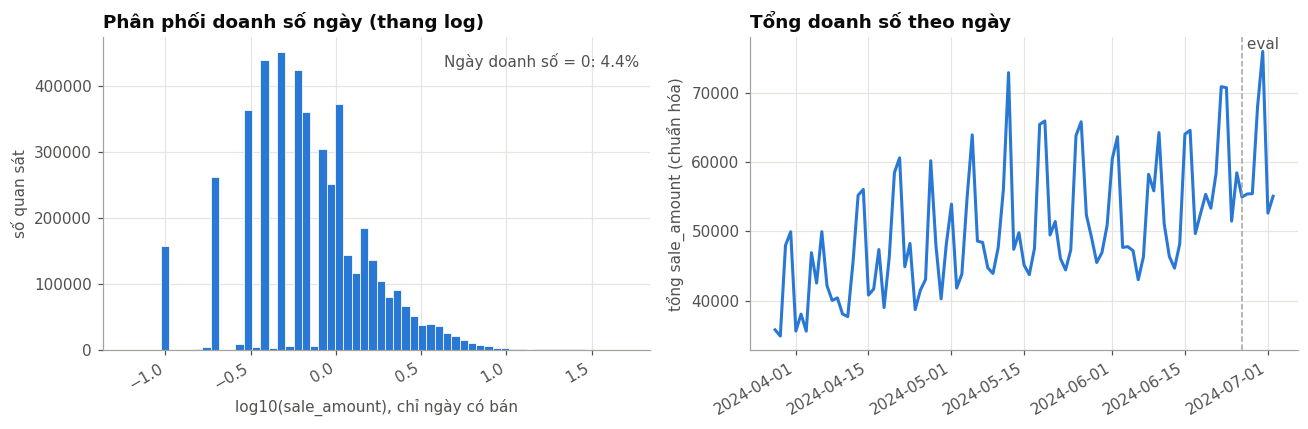

In [8]:
# Cầu tương đối: chuẩn hóa theo chuỗi, chỉ dùng ngày không hết hàng làm mốc
base = df.loc[df.stock_hour6_22_cnt == 0].groupby("series_id").sale_amount.mean()
df["rel_demand"] = (df.sale_amount / df.series_id.map(base).replace(0, np.nan)).astype("float32")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pos = df.loc[df.sale_amount > 0, "sale_amount"]
ax[0].hist(np.log10(pos), bins=60, color=C1, edgecolor="white", linewidth=0.5)
ax[0].set_title("Phân phối doanh số ngày (thang log)")
ax[0].set_xlabel("log10(sale_amount), chỉ ngày có bán"); ax[0].set_ylabel("số quan sát")
ax[0].text(0.98, 0.95, f"Ngày doanh số = 0: {(df.sale_amount == 0).mean():.1%}", transform=ax[0].transAxes,
           ha="right", va="top", color=INK2)

daily = df.groupby("dt").sale_amount.sum()
ax[1].plot(daily.index, daily.values, color=C1)
eval_start = df.loc[df.split != "train", "dt"].min()
if pd.notna(eval_start):
    ax[1].axvline(eval_start, color=MUTED, ls="--", lw=1)
    ax[1].text(eval_start, ax[1].get_ylim()[1], " eval", color=INK2, va="top")
ax[1].set_title("Tổng doanh số theo ngày"); ax[1].set_ylabel("tổng sale_amount (chuẩn hóa)")
fig.autofmt_xdate()
save(fig, "eda1_sales_distribution_time")

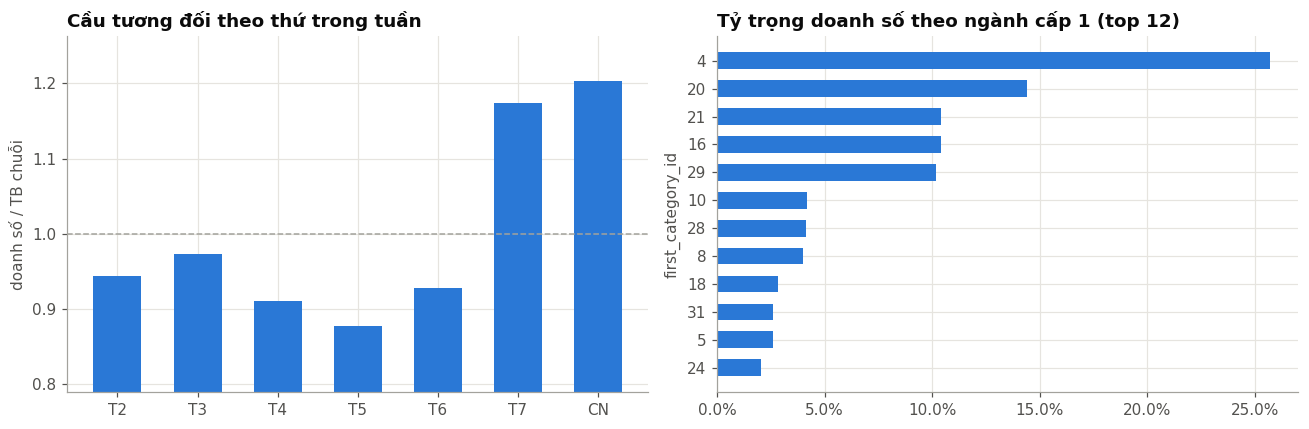

20% sản phẩm bán chạy nhất chiếm 87.1% doanh số; 3 ngành lớn nhất chiếm 50.6%.


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dow_names = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
dow = df.groupby(df.dt.dt.dayofweek).rel_demand.mean()
ax[0].bar([dow_names[i] for i in dow.index], dow.values, color=C1, width=0.6)
ax[0].axhline(1, color=MUTED, ls="--", lw=1)
ax[0].set_title("Cầu tương đối theo thứ trong tuần"); ax[0].set_ylabel("doanh số / TB chuỗi")
ax[0].set_ylim(dow.min() * 0.9, dow.max() * 1.05)

cat_share = df.groupby("first_category_id").sale_amount.sum().sort_values(ascending=False)
cat_share = cat_share / cat_share.sum()
top = cat_share.head(12)
ax[1].barh([str(i) for i in top.index[::-1]], top.values[::-1], color=C1, height=0.6)
pct_axis(ax[1], "x")
ax[1].set_title("Tỷ trọng doanh số theo ngành cấp 1 (top 12)"); ax[1].set_ylabel("first_category_id")
save(fig, "eda1_sales_dow_category")

prod_sales = df.groupby("product_id").sale_amount.sum().sort_values(ascending=False)
top20 = prod_sales.head(int(np.ceil(0.2 * len(prod_sales)))).sum() / prod_sales.sum()
SUMMARY["sales"] = {"zero_sales_share": float((df.sale_amount == 0).mean()),
                    "top20pct_products_sales_share": float(top20),
                    "top3_category_share": float(cat_share.head(3).sum()),
                    "dow_peak": dow_names[int(dow.idxmax())], "dow_low": dow_names[int(dow.idxmin())]}
print(f"20% sản phẩm bán chạy nhất chiếm {top20:.1%} doanh số; 3 ngành lớn nhất chiếm {cat_share.head(3).sum():.1%}.")

## EDA 2. Discount

`discount` = giá bán / giá niêm yết (1.0 = không giảm). Đây là biến quyết định của bài toán.

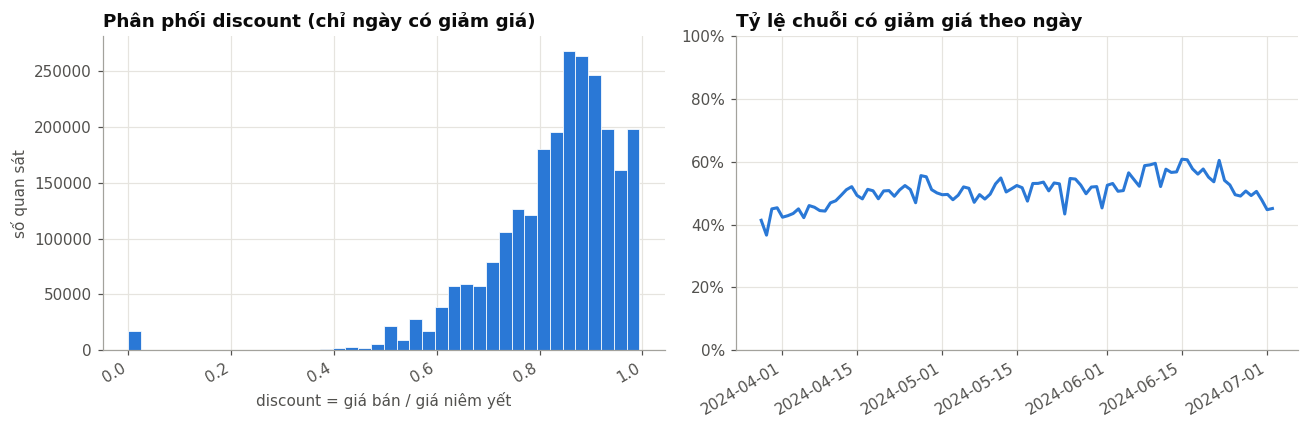

Số mức discount khác nhau mỗi chuỗi (8 = từ 8 trở lên):
n_levels
1     1536
2     1860
3     2616
4     2742
5     2819
6     2966
7     3120
8    32341


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df.loc[df.is_disc == 1, "discount"], bins=40, color=C1, edgecolor="white", linewidth=0.5)
ax[0].set_title("Phân phối discount (chỉ ngày có giảm giá)"); ax[0].set_xlabel("discount = giá bán / giá niêm yết")
ax[0].set_ylabel("số quan sát")

share_t = df.groupby("dt").is_disc.mean()
ax[1].plot(share_t.index, share_t.values, color=C1)
pct_axis(ax[1]); ax[1].set_ylim(0, 1)
ax[1].set_title("Tỷ lệ chuỗi có giảm giá theo ngày")
fig.autofmt_xdate()
save(fig, "eda2_discount_distribution")

lv = ser.n_levels.clip(upper=8).value_counts().sort_index()
print("Số mức discount khác nhau mỗi chuỗi (8 = từ 8 trở lên):")
print(lv.to_string())

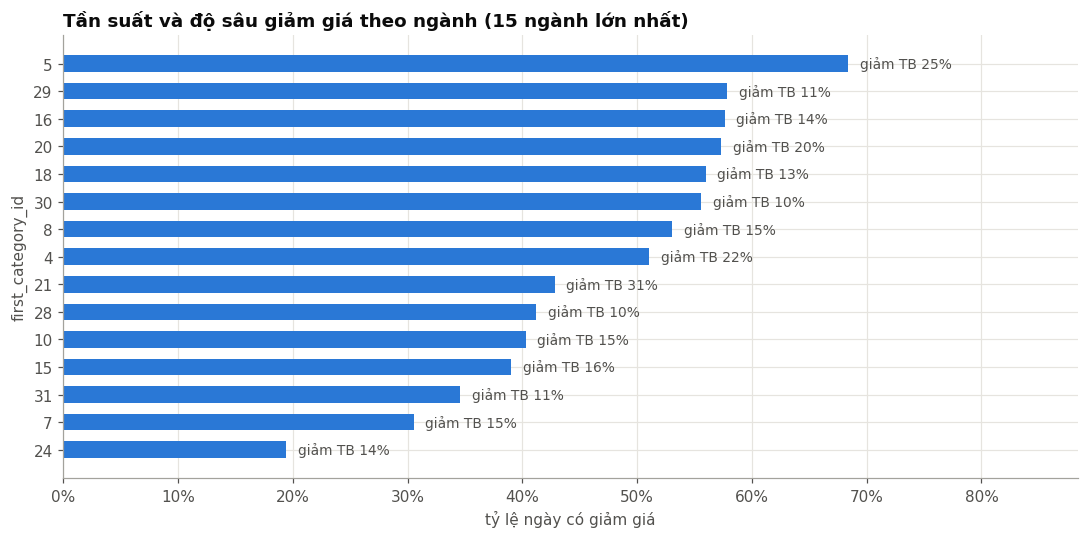

In [11]:
cat_disc = df.groupby("first_category_id").agg(
    share_disc_days=("is_disc", "mean"),
    avg_depth_when_disc=("discount", lambda s: (1 - s[s < 0.995]).mean() if (s < 0.995).any() else 0.0),
    n_rows=("is_disc", "size"),
).sort_values("n_rows", ascending=False)
cat_disc.to_csv(OUT_DIR / "tables" / "discount_by_category.csv")

top = cat_disc.head(15).sort_values("share_disc_days")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh([str(i) for i in top.index], top.share_disc_days, color=C1, height=0.6)
for y, (s, d) in enumerate(zip(top.share_disc_days, top.avg_depth_when_disc)):
    ax.text(s + 0.01, y, f"giảm TB {d:.0%}", va="center", color=INK2, fontsize=9)
pct_axis(ax, "x"); ax.set_xlim(0, min(1, top.share_disc_days.max() + 0.2))
ax.set_title("Tần suất và độ sâu giảm giá theo ngành (15 ngành lớn nhất)")
ax.set_xlabel("tỷ lệ ngày có giảm giá"); ax.set_ylabel("first_category_id")
save(fig, "eda2_discount_by_category")
SUMMARY["discount"] = {"share_rows_discounted": float(df.is_disc.mean()),
                       "share_series_3plus_levels": float((ser.n_levels >= 3).mean()),
                       "share_series_never_discounted": float((ser.n_levels == 1).mean()),
                       "avg_depth_when_discounted": float((1 - df.loc[df.is_disc == 1, "discount"]).mean())}

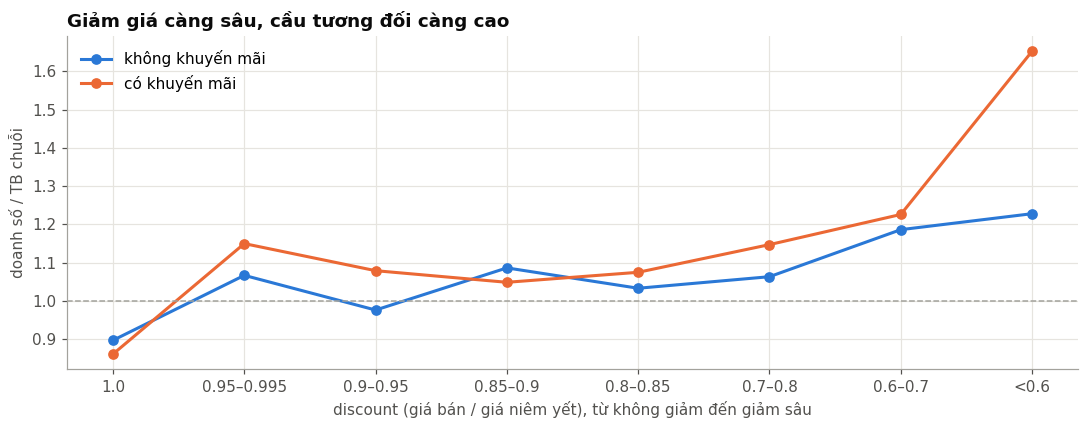

activity_flag,0,1
disc_bin,,
<0.6,1.2278,1.6527
0.6–0.7,1.1860,1.2258
0.7–0.8,1.0630,1.1469
0.8–0.85,1.0328,1.0745
0.85–0.9,1.0860,1.0484
0.9–0.95,0.9758,1.0787
0.95–0.995,1.0665,1.1496
1.0,0.8966,0.8606


In [12]:
# Quan hệ discount – cầu (ngày không hết hàng), tách theo khuyến mãi
BINS = [0, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.995, 1.01]
LABELS = ["<0.6", "0.6–0.7", "0.7–0.8", "0.8–0.85", "0.85–0.9", "0.9–0.95", "0.95–0.995", "1.0"]
df["disc_bin"] = pd.cut(df.discount, bins=BINS, labels=LABELS)
clean = df[df.stock_hour6_22_cnt == 0]
g = clean.groupby(["disc_bin", "activity_flag"], observed=True).rel_demand.agg(["mean", "count"]).reset_index()

ORDER = LABELS[::-1]                      # từ không giảm (1.0) sang giảm sâu nhất
pos_of = {lab: i for i, lab in enumerate(ORDER)}
fig, ax = plt.subplots()
for a, color, name in [(0, C1, "không khuyến mãi"), (1, C2, "có khuyến mãi")]:
    gg = g[(g.activity_flag == a) & (g["count"] >= 500)].copy()
    gg["x"] = gg.disc_bin.astype(str).map(pos_of)
    gg = gg.sort_values("x")
    ax.plot(gg["x"], gg["mean"], marker="o", color=color, label=name)
ax.set_xticks(range(len(ORDER)), ORDER)
ax.axhline(1, color=MUTED, ls="--", lw=1)
ax.set_title("Giảm giá càng sâu, cầu tương đối càng cao")
ax.set_xlabel("discount (giá bán / giá niêm yết), từ không giảm đến giảm sâu"); ax.set_ylabel("doanh số / TB chuỗi")
ax.legend()
save(fig, "eda2_discount_vs_demand")
g.pivot(index="disc_bin", columns="activity_flag", values="mean")

## EDA 3. Stockout (cầu bị che khuất)

Khi hết hàng, `sale_amount` chỉ là giới hạn dưới của cầu thật. Phần này đo mức độ phổ biến và mức độ làm lệch doanh số quan sát.

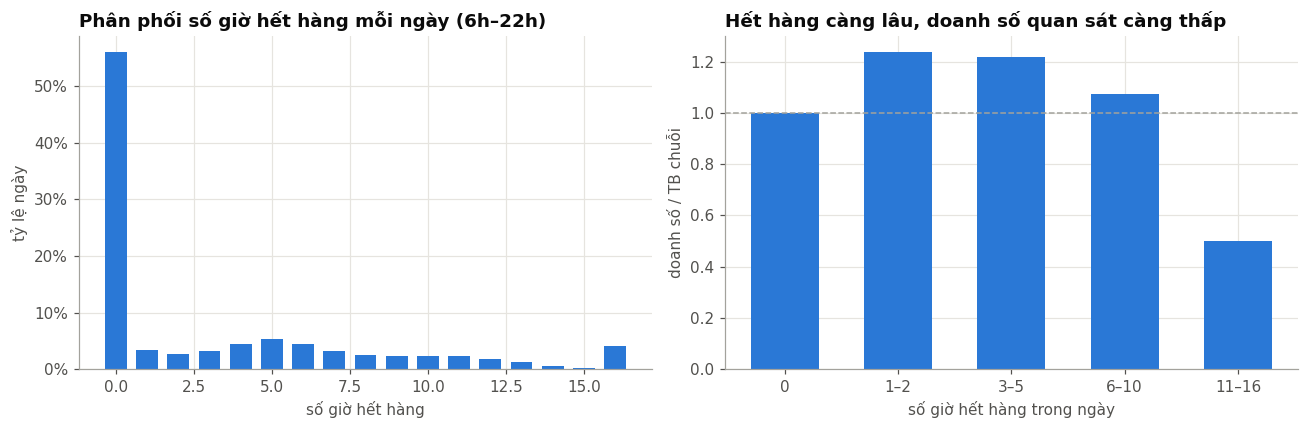

Ngày có hết hàng: 44.0% | hết hàng ≥ 8 giờ: 17.4%


In [13]:
so = df.stock_hour6_22_cnt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
vc = so.value_counts(normalize=True).sort_index()
ax[0].bar(vc.index, vc.values, color=C1, width=0.7)
pct_axis(ax[0]); ax[0].set_title("Phân phối số giờ hết hàng mỗi ngày (6h–22h)")
ax[0].set_xlabel("số giờ hết hàng"); ax[0].set_ylabel("tỷ lệ ngày")

SO_BINS = [-1, 0, 2, 5, 10, 16]
SO_LABELS = ["0", "1–2", "3–5", "6–10", "11–16"]
rel_so = df.groupby(pd.cut(so, SO_BINS, labels=SO_LABELS), observed=True).rel_demand.mean()
ax[1].bar(rel_so.index.astype(str), rel_so.values, color=C1, width=0.6)
ax[1].axhline(1, color=MUTED, ls="--", lw=1)
ax[1].set_title("Hết hàng càng lâu, doanh số quan sát càng thấp")
ax[1].set_xlabel("số giờ hết hàng trong ngày"); ax[1].set_ylabel("doanh số / TB chuỗi")
save(fig, "eda3_stockout")

ser_so = (so > 0).groupby(df.series_id).mean()
SUMMARY["stockout"] = {"share_days_any_stockout": float((so > 0).mean()),
                       f"share_days_stockout_ge_{STOCKOUT_HEAVY_HOURS}h": float((so >= STOCKOUT_HEAVY_HOURS).mean()),
                       "share_series_stockout_over_half_days": float((ser_so > 0.5).mean()),
                       "rel_demand_by_stockout_hours": {k: float(v) for k, v in rel_so.items()}}
print(f"Ngày có hết hàng: {(so > 0).mean():.1%} | hết hàng ≥ {STOCKOUT_HEAVY_HOURS} giờ: {(so >= STOCKOUT_HEAVY_HOURS).mean():.1%}")

24 giờ/ngày | corr(tổng giờ trạng thái, stock_hour6_22_cnt) = 1.000 → hours_stock_status = 1 nghĩa là HẾT hàng


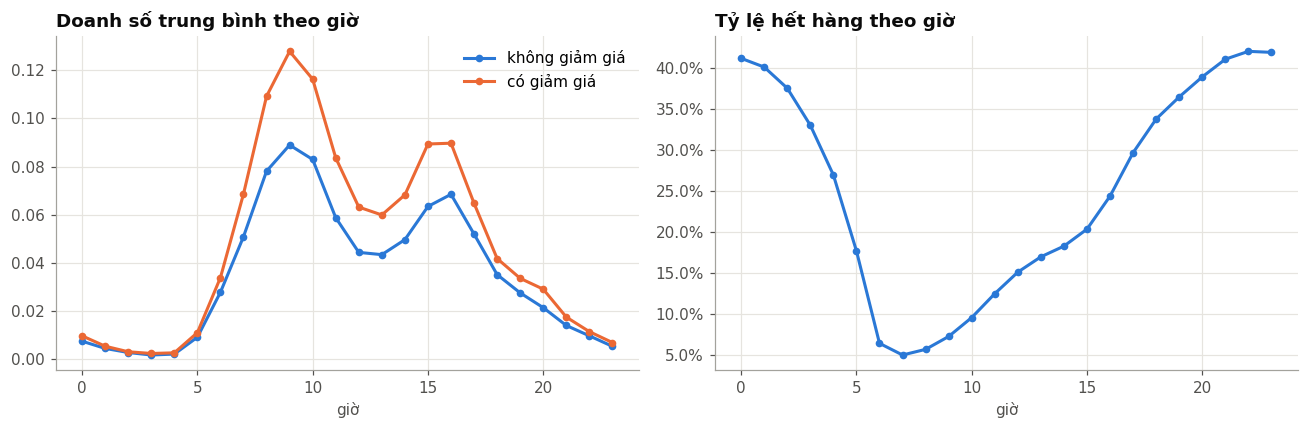

In [14]:
# Mẫu hình theo giờ trên một mẫu ngẫu nhiên
N_SAMPLE = 30_000
tr = ds["train"]
idx = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(tr), size=min(N_SAMPLE, len(tr)), replace=False))
hs = tr.select(idx).select_columns(["discount", "stock_hour6_22_cnt"] + HOURLY_COLS).to_pandas()
L = int(pd.Series([len(x) for x in hs.hours_sale]).mode()[0])
hs = hs[[len(x) == L and len(y) == L for x, y in zip(hs.hours_sale, hs.hours_stock_status)]]
H = np.stack(hs.hours_sale.values).astype(float)
S = np.stack(hs.hours_stock_status.values).astype(float)

# Xác định quy ước của hours_stock_status bằng cách đối chiếu với stock_hour6_22_cnt
r = np.corrcoef(S[:, 6:22].sum(1), hs.stock_hour6_22_cnt)[0, 1] if L >= 22 else np.nan
STOCKOUT_IS_1 = bool(r > 0)
OUT = S if STOCKOUT_IS_1 else 1 - S
print(f"{L} giờ/ngày | corr(tổng giờ trạng thái, stock_hour6_22_cnt) = {r:.3f} → "
      f"hours_stock_status = 1 nghĩa là {'HẾT hàng' if STOCKOUT_IS_1 else 'CÒN hàng'}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
disc = (hs.discount < 0.995).values
ax[0].plot(H[~disc].mean(0), color=C1, marker="o", markersize=4, label="không giảm giá")
ax[0].plot(H[disc].mean(0), color=C2, marker="o", markersize=4, label="có giảm giá")
ax[0].set_title("Doanh số trung bình theo giờ"); ax[0].set_xlabel("giờ"); ax[0].legend()
ax[1].plot(OUT.mean(0), color=C1, marker="o", markersize=4)
pct_axis(ax[1]); ax[1].set_title("Tỷ lệ hết hàng theo giờ"); ax[1].set_xlabel("giờ")
save(fig, "eda3_hourly_profile")
SUMMARY["hourly"] = {"hours_per_day": L, "hours_stock_status_1_means_stockout": STOCKOUT_IS_1,
                     "peak_sales_hour": int(H.mean(0).argmax()), "peak_stockout_hour": int(OUT.mean(0).argmax())}

## EDA 4. Promotion, holiday và thời tiết

Cầu tương đối theo khuyến mãi × giảm giá (ngày không hết hàng):


,không giảm giá,có giảm giá
không khuyến mãi,0.8966,1.0348
có khuyến mãi,0.8606,1.1350


Ngày giảm giá KHÔNG trùng khuyến mãi: 27.9%


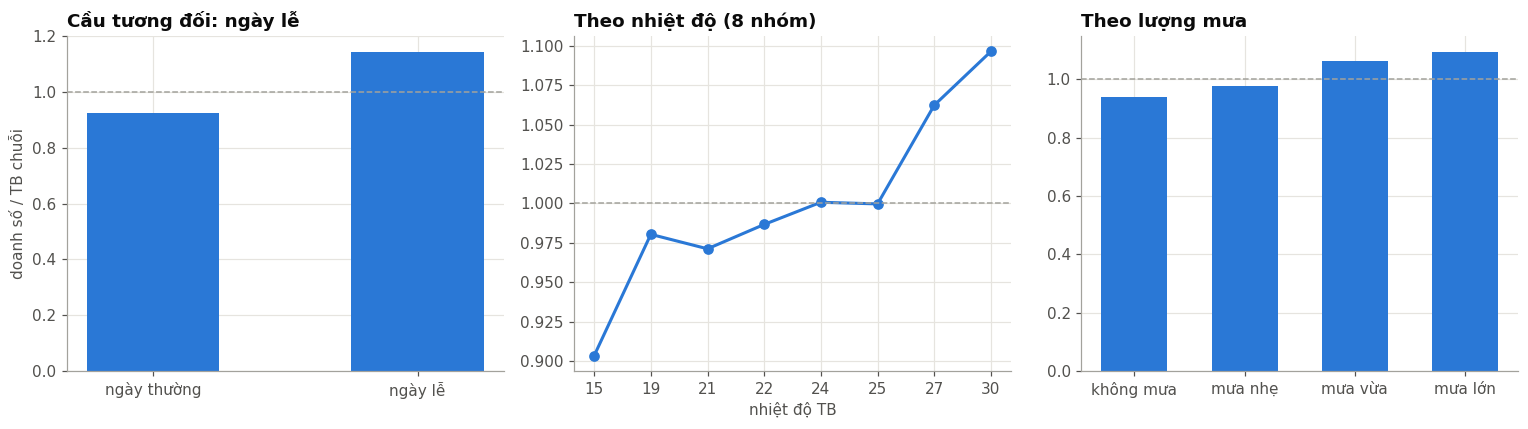

In [15]:
clean = df[df.stock_hour6_22_cnt == 0]
promo_tbl = clean.pivot_table(index="activity_flag", columns="is_disc", values="rel_demand", aggfunc="mean")
promo_tbl.index = ["không khuyến mãi", "có khuyến mãi"][: len(promo_tbl)]
promo_tbl.columns = ["không giảm giá", "có giảm giá"][: promo_tbl.shape[1]]
print("Cầu tương đối theo khuyến mãi × giảm giá (ngày không hết hàng):")
display(promo_tbl)

overlap = pd.crosstab(df.is_disc, df.activity_flag, normalize="index")
share_disc_no_act = float((df.loc[df.is_disc == 1, "activity_flag"] == 0).mean())
print(f"Ngày giảm giá KHÔNG trùng khuyến mãi: {share_disc_no_act:.1%}")

hol = clean.groupby("holiday_flag").rel_demand.mean()
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].bar(["ngày thường", "ngày lễ"][: len(hol)], hol.values, color=C1, width=0.5)
ax[0].axhline(1, color=MUTED, ls="--", lw=1); ax[0].set_title("Cầu tương đối: ngày lễ")
ax[0].set_ylabel("doanh số / TB chuỗi")

t_bin = pd.qcut(clean.avg_temperature, 8, duplicates="drop")
temp = clean.groupby(t_bin, observed=True).rel_demand.mean()
ax[1].plot([f"{iv.mid:.0f}" for iv in temp.index], temp.values, color=C1, marker="o")
ax[1].axhline(1, color=MUTED, ls="--", lw=1); ax[1].set_title("Theo nhiệt độ (8 nhóm)"); ax[1].set_xlabel("nhiệt độ TB")

p_bin = pd.cut(clean.precpt, [-0.01, 0, clean.precpt.quantile(0.75), clean.precpt.quantile(0.95), np.inf],
               labels=["không mưa", "mưa nhẹ", "mưa vừa", "mưa lớn"], duplicates="drop")
rain = clean.groupby(p_bin, observed=True).rel_demand.mean()
ax[2].bar(rain.index.astype(str), rain.values, color=C1, width=0.6)
ax[2].axhline(1, color=MUTED, ls="--", lw=1); ax[2].set_title("Theo lượng mưa")
save(fig, "eda4_holiday_weather")

SUMMARY["promotion_holiday"] = {"share_disc_days_without_activity": share_disc_no_act,
                                "rel_demand_promo_x_disc": {f"{i}|{c}": float(promo_tbl.loc[i, c]) for i in promo_tbl.index for c in promo_tbl.columns},
                                "rel_demand_holiday": {str(k): float(v) for k, v in hol.items()}}

## EDA 5. Price elasticity

Hồi quy log-log có fixed effects theo chuỗi (so sánh trong cùng cửa hàng × sản phẩm), trên ngày không hết hàng của các chuỗi có ít nhất 2 mức discount:

`log(sales) = β · log(discount) + γ₁·activity + γ₂·holiday + thứ + thời tiết + α_chuỗi + ε`

β là **độ co giãn của cầu theo giá**. Sai số chuẩn được tính **cluster theo chuỗi**, vì các ngày trong cùng một chuỗi tương quan với nhau; sai số chuẩn cổ điển sẽ quá lạc quan.

In [16]:
def fe_elasticity(data, min_rows=500):
    if len(data) < min_rows:
        return None
    eps = 0.01 * data.loc[data.sale_amount > 0, "sale_amount"].mean()
    y = np.log(data.sale_amount.to_numpy(dtype="float64") + eps)
    X = pd.DataFrame({
        "log_price": np.log(data.discount.to_numpy(dtype="float64")),
        "activity": data.activity_flag.to_numpy(dtype="float64"),
        "holiday": data.holiday_flag.to_numpy(dtype="float64"),
        "precpt": data.precpt.to_numpy(dtype="float64"),
        "temp": data.avg_temperature.to_numpy(dtype="float64"),
    })
    dow = pd.get_dummies(data.dt.dt.dayofweek.to_numpy(), prefix="dow", drop_first=True).astype(float)
    X = pd.concat([X, dow], axis=1)
    sid = data.series_id.to_numpy()
    Xd = X - X.groupby(sid).transform("mean")
    yd = y - pd.Series(y).groupby(sid).transform("mean").to_numpy()
    Xd = Xd.loc[:, Xd.std() > 1e-9]
    if "log_price" not in Xd:
        return None
    A = Xd.to_numpy()
    XtX_inv = np.linalg.pinv(A.T @ A)
    beta = XtX_inv @ (A.T @ yd)
    u = yd - A @ beta
    n, k = A.shape
    G = len(np.unique(sid))
    # Sai số chuẩn cổ điển (để so sánh)
    se_classic = np.sqrt(np.diag(XtX_inv) * (u @ u) / max(n - k - G, 1))
    # Sai số chuẩn cluster theo chuỗi (sandwich)
    scores = pd.DataFrame(A * u[:, None]).groupby(sid).sum().to_numpy()
    V = XtX_inv @ (scores.T @ scores) @ XtX_inv * (G / max(G - 1, 1)) * ((n - 1) / max(n - k, 1))
    se = np.sqrt(np.diag(V))
    j = list(Xd.columns).index("log_price")
    coefs = dict(zip(Xd.columns, beta))
    return {"elasticity": beta[j], "se_cluster": se[j], "t_cluster": beta[j] / se[j],
            "ci_low": beta[j] - 1.96 * se[j], "ci_high": beta[j] + 1.96 * se[j],
            "t_classic": beta[j] / se_classic[j], "activity_coef": coefs.get("activity", np.nan),
            "n_rows": n, "n_series": G}

valid = ser.index[ser.n_levels >= 2]
d = df[df.series_id.isin(valid) & (df.stock_hour6_22_cnt == 0)
       & (df.discount >= MIN_VALID_DISCOUNT) & (df.discount <= 1)].reset_index(drop=True)
print(f"Loại khỏi hồi quy các dòng discount < {MIN_VALID_DISCOUNT} hoặc > 1: "
      f"{int(((df.discount < MIN_VALID_DISCOUNT) | (df.discount > 1)).sum()):,} dòng trong toàn bộ dữ liệu")
print(f"Mẫu ước lượng: {len(d):,} dòng, {d.series_id.nunique():,} chuỗi")

overall = fe_elasticity(d)
print(pd.Series(overall).to_string())
print(f"\n→ Giảm giá 10% thì cầu thay đổi khoảng {(0.9 ** overall['elasticity'] - 1):+.1%} "
      f"(KTC 95%: {(0.9 ** overall['ci_high'] - 1):+.1%} đến {(0.9 ** overall['ci_low'] - 1):+.1%})")
SUMMARY["elasticity_overall"] = {k: float(v) for k, v in overall.items()}

Loại khỏi hồi quy các dòng discount < 0.3 hoặc > 1: 17,718 dòng trong toàn bộ dữ liệu
Mẫu ước lượng: 2,632,966 dòng, 48,397 chuỗi
elasticity             -2.0070
se_cluster              0.0249
t_cluster             -80.6894
ci_low                 -2.0558
ci_high                -1.9583
t_classic            -338.4344
activity_coef           0.0124
n_rows          2,632,966.0000
n_series           48,397.0000

→ Giảm giá 10% thì cầu thay đổi khoảng +23.5% (KTC 95%: +22.9% đến +24.2%)


In [17]:
MIN_SERIES = 50
def classify(r):
    if r["n_series"] < MIN_SERIES or abs(r["t_cluster"]) < 2 or r["elasticity"] >= 0:
        return "Chưa kết luận"
    if r["elasticity"] > -1:
        return "Ít co giãn"
    if r["elasticity"] >= -2.5:
        return "Co giãn vừa"
    return "Rất co giãn"

rows = []
for cat, dd in d.groupby("first_category_id"):
    r = fe_elasticity(dd.reset_index(drop=True))
    if r:
        rows.append({"first_category_id": cat, **r})
el = pd.DataFrame(rows)
el["nhom"] = el.apply(classify, axis=1)
el = el.sort_values("elasticity").reset_index(drop=True)
el.to_csv(OUT_DIR / "tables" / "elasticity_by_category.csv", index=False)
print("Số ngành theo nhóm:")
print(el.nhom.value_counts().to_string())
el[["first_category_id", "elasticity", "ci_low", "ci_high", "t_cluster", "n_series", "nhom"]]

Số ngành theo nhóm:
nhom
Co giãn vừa      11
Rất co giãn       8
Ít co giãn        5
Chưa kết luận     4


,first_category_id,elasticity,ci_low,ci_high,t_cluster,n_series,nhom
0,26,-7.7241,-9.5176,-5.9305,-8.4407,30,Chưa kết luận
1,28,-5.4872,-5.7754,-5.1991,-37.3245,1853,Rất co giãn
2,5,-5.1744,-5.2583,-5.0905,-120.9449,1630,Rất co giãn
3,29,-4.4311,-4.5770,-4.2852,-59.5181,3489,Rất co giãn
4,15,-3.1724,-3.3269,-3.0179,-40.2352,692,Rất co giãn
5,3,-3.0351,-3.6565,-2.4137,-9.5728,82,Rất co giãn
6,24,-2.7213,-2.9024,-2.5402,-29.4527,1295,Rất co giãn
7,17,-2.6260,-3.3645,-1.8875,-6.9695,72,Rất co giãn
8,0,-2.6071,-2.9850,-2.2292,-13.5211,355,Rất co giãn
9,13,-2.5359,-3.4689,-1.6030,-5.3277,23,Chưa kết luận


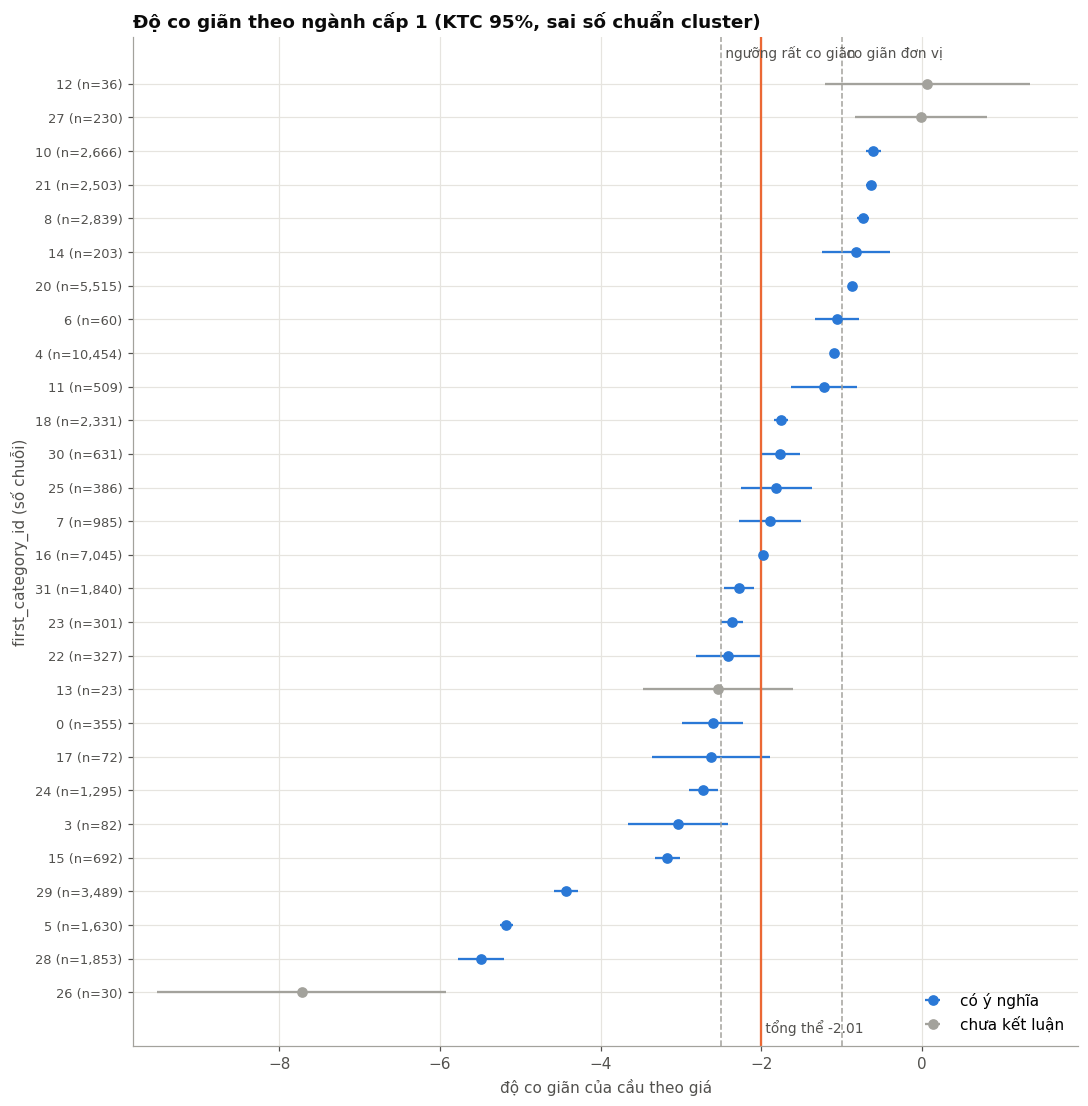

In [18]:
fig, ax = plt.subplots(figsize=(10, max(4, 0.32 * len(el) + 1.2)))
ok = el.nhom != "Chưa kết luận"
y = np.arange(len(el))
for mask, color, name in [(ok, C1, "có ý nghĩa"), (~ok, MUTED, "chưa kết luận")]:
    if not mask.any():
        continue
    ax.errorbar(el.loc[mask, "elasticity"], y[mask],
                xerr=[el.loc[mask, "elasticity"] - el.loc[mask, "ci_low"], el.loc[mask, "ci_high"] - el.loc[mask, "elasticity"]],
                fmt="o", color=color, ecolor=color, elinewidth=1.5, capsize=0, markersize=6, label=name)
for x, txt in [(-1, "co giãn đơn vị"), (-2.5, "ngưỡng rất co giãn")]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
    ax.text(x, len(el) - 0.3, f" {txt}", color=INK2, fontsize=9, va="bottom")
ax.axvline(overall["elasticity"], color=C2, lw=1.5)
ax.text(overall["elasticity"], -1.2, f" tổng thể {overall['elasticity']:.2f}", color=INK2, fontsize=9)
ax.set_yticks(y, [f"{c} (n={n:,})" for c, n in zip(el.first_category_id, el.n_series)], fontsize=8.5)
ax.set_ylim(-1.6, len(el) + 0.4)
ax.set_xlim(min(el.ci_low.min(), -2.5) - 0.3, max(el.ci_high.max(), -1) + 0.6)
ax.set_title("Độ co giãn theo ngành cấp 1 (KTC 95%, sai số chuẩn cluster)")
ax.set_xlabel("độ co giãn của cầu theo giá"); ax.set_ylabel("first_category_id (số chuỗi)")
ax.legend(loc="lower right")
save(fig, "eda5_elasticity_by_category")
SUMMARY["elasticity_groups"] = {g: sorted(int(c) for c in el.loc[el.nhom == g, "first_category_id"]) for g in el.nhom.unique()}

## Tổng kết

Các con số dưới đây đi thẳng vào mục 3.1–3.2 của báo cáo. Bảng độ co giãn theo ngành (`elasticity_by_category.csv`) được dùng lại ở Chương 5 (phân tích độ nhạy theo nhóm ngành) và trong demo.

In [19]:
def fmt(v):
    return f"{v:.1%}" if isinstance(v, float) and 0 <= v <= 1 else v

e = SUMMARY["elasticity_overall"]
findings = [
    ("Dữ liệu", f"{len(df):,} quan sát, {df.series_id.nunique():,} chuỗi, {df.dt.nunique()} ngày; "
                f"{SUMMARY['quality']['missing_cells']} ô thiếu, {SUMMARY['quality']['duplicate_store_product_day']} dòng trùng"),
    ("Sales", f"20% sản phẩm chiếm {fmt(SUMMARY['sales']['top20pct_products_sales_share'])} doanh số; "
              f"cao nhất {SUMMARY['sales']['dow_peak']}, thấp nhất {SUMMARY['sales']['dow_low']}"),
    ("Discount", f"{fmt(SUMMARY['discount']['share_rows_discounted'])} số ngày có giảm giá, độ sâu TB "
                 f"{fmt(SUMMARY['discount']['avg_depth_when_discounted'])}; {fmt(SUMMARY['discount']['share_series_3plus_levels'])} chuỗi có ≥ 3 mức"),
    ("Stockout", f"{fmt(SUMMARY['stockout']['share_days_any_stockout'])} số ngày hết hàng ≥ 1 giờ → cần xử lý cầu bị che khuất"),
    ("Promotion", f"chỉ {fmt(SUMMARY['promotion_holiday']['share_disc_days_without_activity'])} ngày giảm giá không trùng khuyến mãi → phải kiểm soát activity_flag"),
    ("Elasticity", f"{e['elasticity']:.2f} (KTC 95% {e['ci_low']:.2f} đến {e['ci_high']:.2f}, t cluster = {e['t_cluster']:.1f})"),
    ("Theo ngành", "; ".join(f"{g}: {len(v)} ngành" for g, v in SUMMARY["elasticity_groups"].items())),
]
display(pd.DataFrame(findings, columns=["Chủ đề", "Phát hiện"]))

with open(OUT_DIR / "tables" / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(SUMMARY, f, ensure_ascii=False, indent=2, default=str)
print("Đã lưu:")
for p in sorted((OUT_DIR / "figures").glob("*.png")) + sorted((OUT_DIR / "tables").glob("*")):
    print("  ", p.relative_to(OUT_DIR))

,Chủ đề,Phát hiện
0,Dữ liệu,"4,850,000 quan sát, 50,000 chuỗi, 97 ngày; 0 ô..."
1,Sales,20% sản phẩm chiếm 87.1% doanh số; cao nhất CN...
2,Discount,"50.8% số ngày có giảm giá, độ sâu TB 17.3%; 93..."
3,Stockout,44.0% số ngày hết hàng ≥ 1 giờ → cần xử lý cầu...
4,Promotion,chỉ 27.9% ngày giảm giá không trùng khuyến mãi...
5,Elasticity,"-2.01 (KTC 95% -2.06 đến -1.96, t cluster = -8..."
6,Theo ngành,Chưa kết luận: 4 ngành; Rất co giãn: 8 ngành; ...


Đã lưu:
   figures/eda1_sales_distribution_time.png
   figures/eda1_sales_dow_category.png
   figures/eda2_discount_by_category.png
   figures/eda2_discount_distribution.png
   figures/eda2_discount_vs_demand.png
   figures/eda3_hourly_profile.png
   figures/eda3_stockout.png
   figures/eda4_holiday_weather.png
   figures/eda5_elasticity_by_category.png
   figures/fc_actual_vs_pred.png
   figures/fc_feature_importance.png
   figures/fc_optuna_history.png
   figures/fc_price_response.png
   figures/opt_distribution_and_uplift.png
   figures/opt_example_profit_curve.png
   figures/prep_censoring_recovery.png
   figures/prep_hourly_profile.png
   figures/prep_time_split.png
   figures/res_cost_sensitivity.png
   figures/res_cross_evaluation.png
   tables/discount_by_category.csv
   tables/eda_summary.json
   tables/elasticity_by_category.csv
   tables/fc_summary.csv
   tables/opt_summary.csv
   tables/optuna_trials.csv
   tables/prep_log.json
   tables/prep_min_avail_sensitivity.csv
   ta